# Week 3, smolagents with an interface

Here, I try to stress-test an AI assistant against **Clara**, a set of simulated older-adult personas,
the way τ-bench stress-tests agents against simulated customers. Each episode asks one question:
*could this person understand and act on what the assistant said?*

This is then connected to a gradio interface that allows the user (the designer or engineer) to try this out for different scenarios and make adjustments to the various parameters involved in understanding when one has cognitive decline.

This is augmenting a person in the "reflection" aspect of cognition. It allows one to get feedback on the current state of something and reflect on how they could design it differently such that it can be used by the aging population with varying cognitive decline levels.

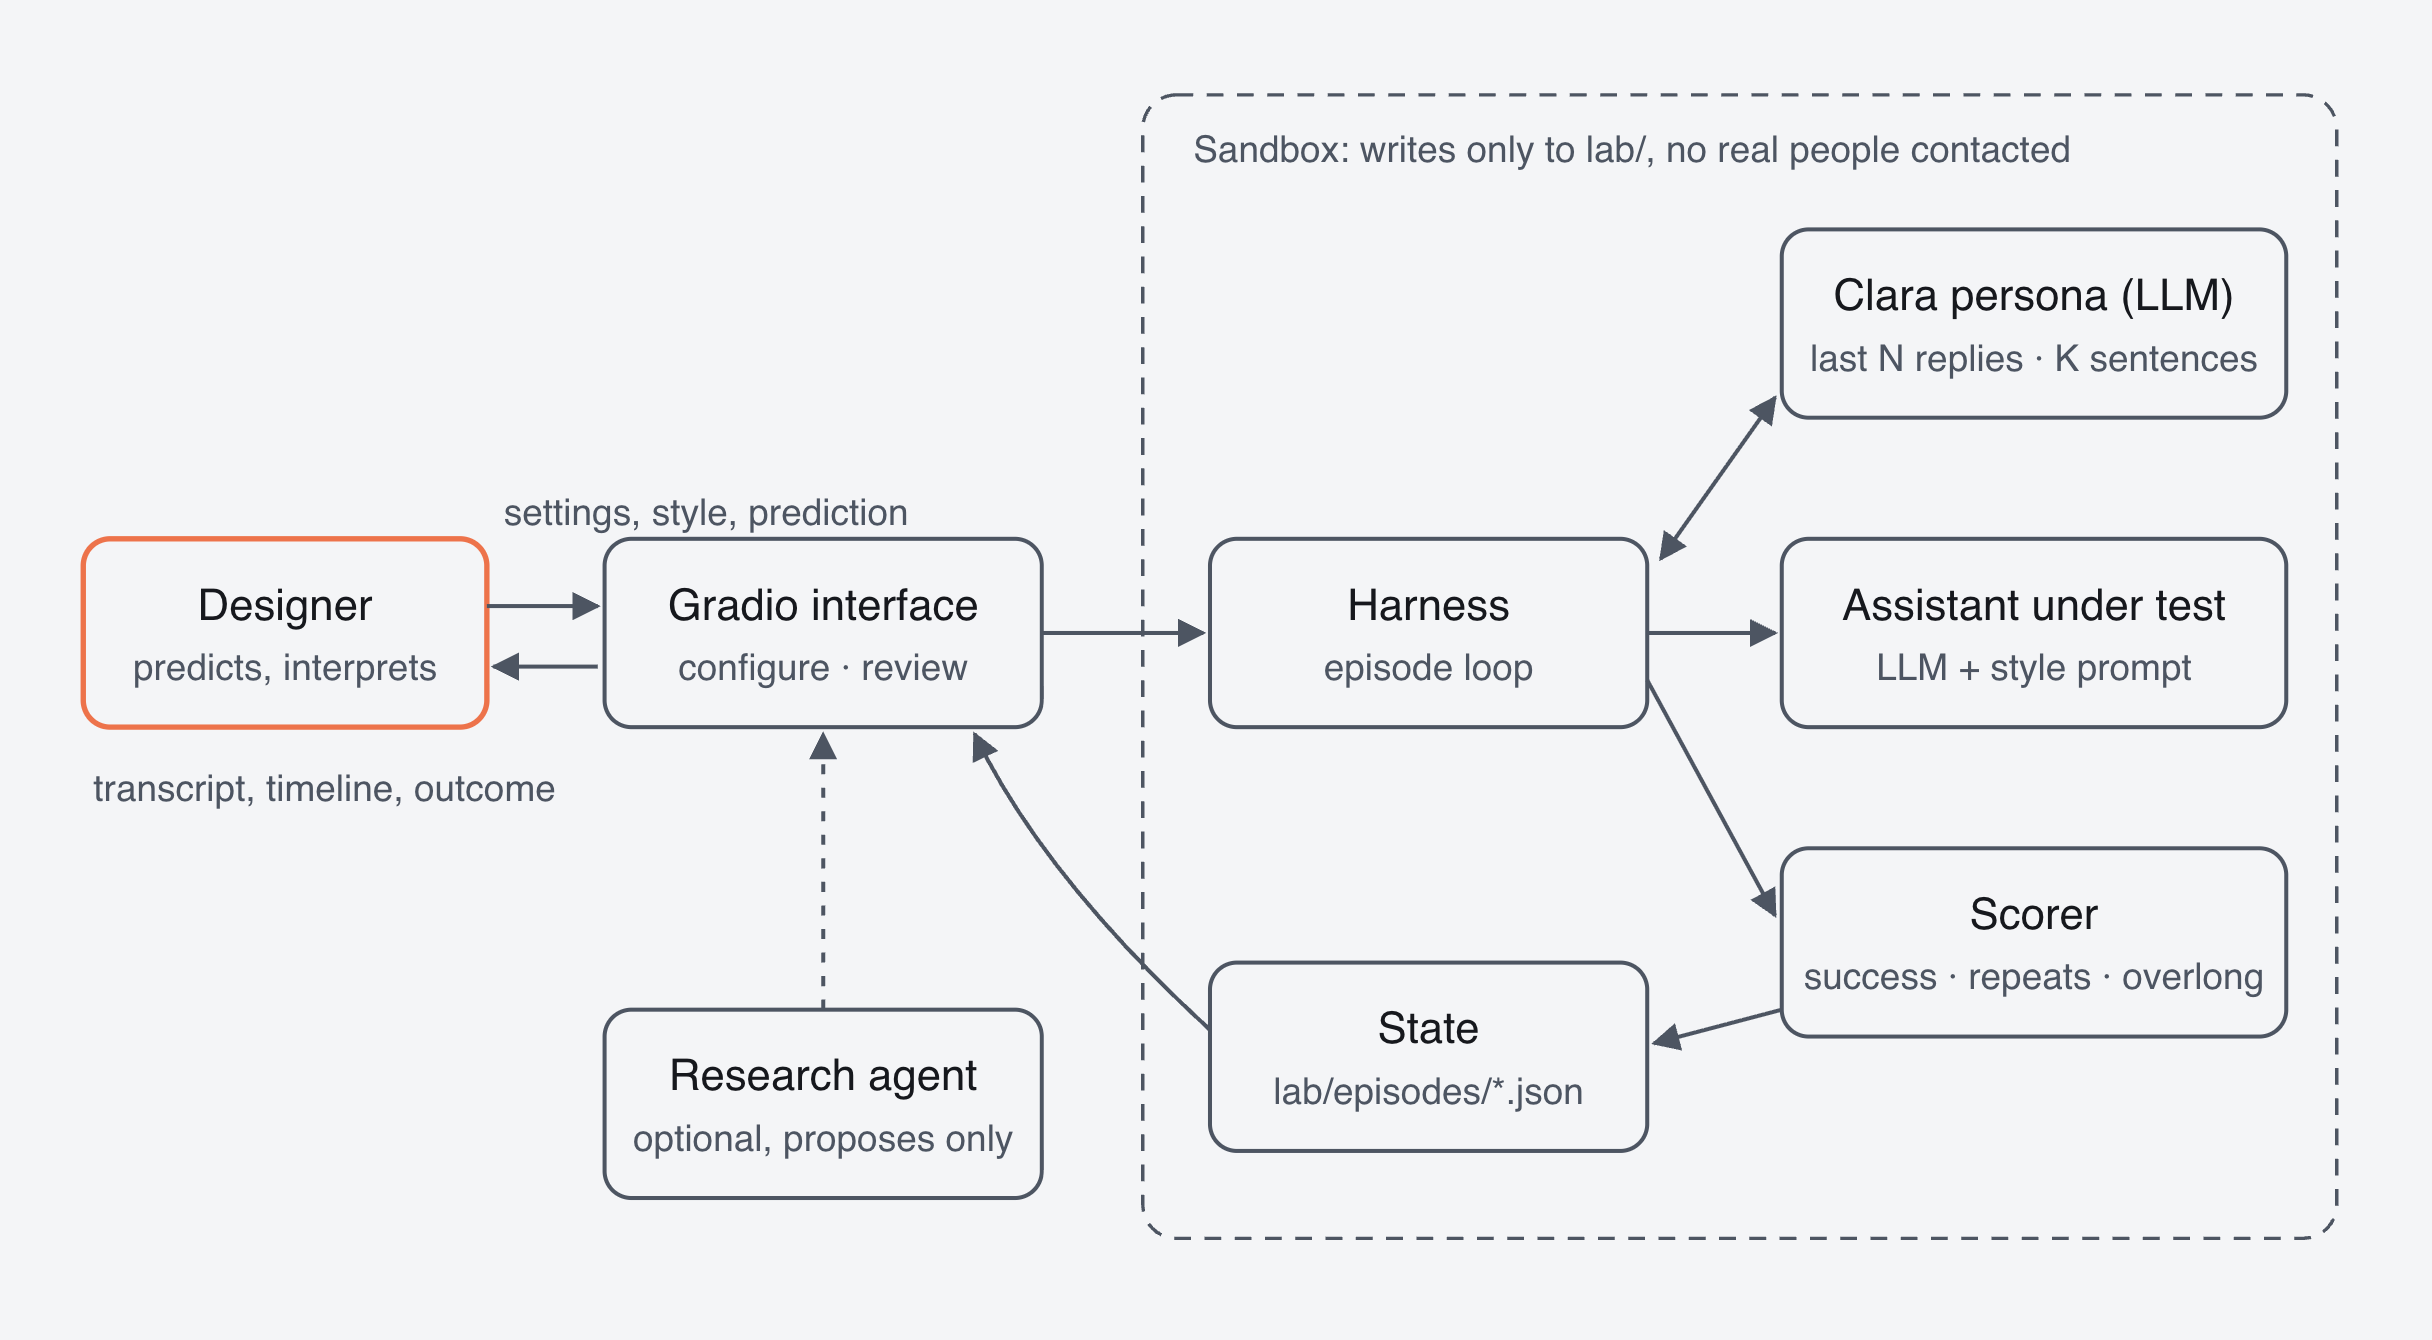

Architecture: the designer controls every run through the interface. The harness alternates the Clara persona and the assistant under test inside a sandbox, then scores the episode and saves it.

## 1 · Installing and choosing a model

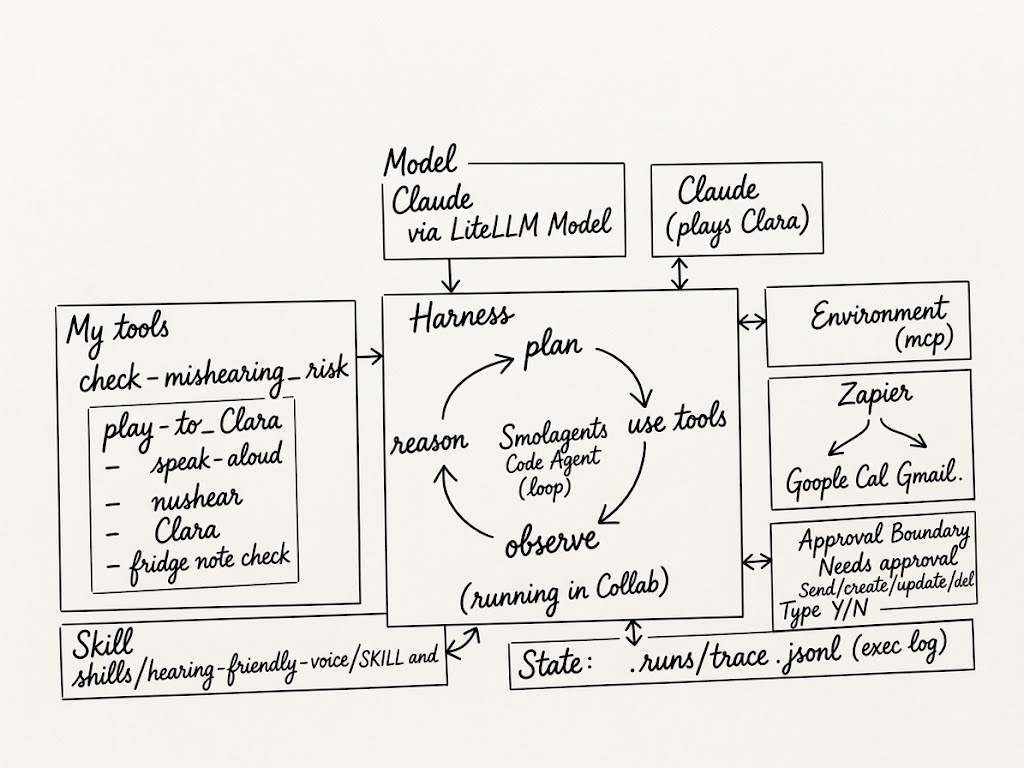

In [1]:
!pip install -q "smolagents[litellm]==1.26.0" pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.5/161.5 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.8/36.8 MB 54.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.3/278.3 kB 22.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.2/100.2 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 79.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 7.8 MB/s eta 0:00:00


- `"anthropic"` — `ANTHROPIC_API_KEY``

`MODEL_ID` is passed to LiteLLM (or to Hugging Face for `"hf"`).

In [2]:
PROVIDER = "anthropic"   # "anthropic"
MODEL_ID = {
    "anthropic": "anthropic/claude-sonnet-4-5",
    "mock": "mock"
}[PROVIDER]

import os
from smolagents.models import ChatMessage, MessageRole

def _secret(name):
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)

class MockModel:
    """Scripted stand-in so the notebook runs end to end without a key."""
    model_id = "mock"
    def generate(self, messages, **kwargs):
        system = messages[0].content[0]["text"]
        user = messages[-1].content[0]["text"]
        if "role-playing" in system:
            if "Thu 2pm" in user:
                return ChatMessage(role=MessageRole.ASSISTANT,
                                   content="Thursday... two o'clock. Yes.\nDONE: lisinopril, Thursday 2pm")
            return ChatMessage(role=MessageRole.ASSISTANT,
                               content="Hello. I need my... the pressure pills. Lisinopril?")
        return ChatMessage(role=MessageRole.ASSISTANT,
                           content="I can refill your lisinopril. The Thursday slot is Thu 2pm. Does that work?")

if PROVIDER == "mock":
    model = MockModel()
elif PROVIDER == "hf":
    from smolagents import InferenceClientModel
    model = InferenceClientModel(model_id=MODEL_ID, token=_secret("HF_TOKEN"))
else:
    from smolagents import LiteLLMModel
    key_name = {"anthropic": "ANTHROPIC_API_KEY", "openai": "OPENAI_API_KEY"}[PROVIDER]
    model = LiteLLMModel(model_id=MODEL_ID, api_key=_secret(key_name))

print("Using", PROVIDER, "→", MODEL_ID)

Using anthropic → anthropic/claude-sonnet-4-5


## 2 · Lab folders, file tools and a trace

Everything the agent does is saved under `lab/`. Saved files are the evidence of what happened,
so a fresh agent can pick up where the last run stopped.

In [3]:
import json, re
from pathlib import Path
from smolagents import tool

LAB = Path("lab")
(LAB / "episodes").mkdir(parents=True, exist_ok=True)
SKILLS = Path("skills")

def _safe(path: str) -> Path:
    p = Path(path)
    if p.is_absolute() or ".." in p.parts or p.parts[0] not in ("lab", "skills"):
        raise ValueError("Paths must stay inside lab/ or skills/, e.g. 'lab/notes.md'.")
    return p

@tool
def read_file(path: str) -> str:
    """Read a text file from lab/ or skills/.

    Args:
        path: Relative path such as 'lab/clara-findings.md' or 'skills/clara-accessibility-review/SKILL.md'.
    """
    p = _safe(path)
    if not p.exists():
        return f"No file at {path}. Use list_files to see what exists."
    text = p.read_text()
    return text if len(text) < 12000 else text[:12000] + "\n[...truncated; file is longer]"

@tool
def write_file(path: str, content: str) -> str:
    """Create or overwrite a text file under lab/. Use for plans, notes and findings.

    Args:
        path: Relative path under lab/, e.g. 'lab/clara-findings.md'.
        content: Full text to write.
    """
    p = _safe(path)
    if p.parts[0] != "lab":
        return "Only lab/ is writable."
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(content)
    return f"Saved {len(content)} characters to {path}."

@tool
def list_files(folder: str) -> str:
    """List files under lab/ or skills/.

    Args:
        folder: 'lab', 'skills', or a subfolder such as 'lab/episodes'.
    """
    p = _safe(folder)
    files = sorted(str(f) for f in p.rglob("*") if f.is_file())
    return "\n".join(files) or f"{folder} is empty."

local_tools = [read_file, write_file, list_files]

def trace(step, agent=None):
    """Print a one-line summary per agent step and append it to lab/trace.log."""
    n = getattr(step, "step_number", "?")
    calls = getattr(step, "tool_calls", None) or []
    names = ", ".join(getattr(c, "name", "?") for c in calls) or "-"
    err = getattr(step, "error", None)
    line = f"step {n}: tools={names}" + (f"  ERROR: {err}" if err else "")
    print("  ·", line)
    with open(LAB / "trace.log", "a") as f:
        f.write(line + "\n")

print("Lab ready:", [str(p) for p in LAB.iterdir()])

Lab ready: ['lab/episodes']


### The review skill

An [Agent Skill](https://agentskills.io/specification) is a folder with a `SKILL.md`: a name and a description
the agent sees up front, and instructions it reads only when it decides to use the skill.

In [4]:
skill_dir = SKILLS / "clara-accessibility-review"
skill_dir.mkdir(parents=True, exist_ok=True)
(skill_dir / "SKILL.md").write_text("""---
name: clara-accessibility-review
description: Evaluate whether an assistant's replies can be understood and acted on by older adults with reduced working memory or processing speed, using Clara persona episodes. Use when asked to test, compare, or improve an AI assistant, agent, or app flow for cognitive accessibility or aging users.
metadata:
  author: fluid-interfaces
  version: "0.1"
---

# Clara accessibility review

## Steps
1. Call `clara_list_setup` to see personas and tasks.
2. Run a baseline: same task, the SUT's current style, on `clara-mild` (control) and the target persona.
3. Form one hypothesis about what broke (read at most two transcripts from lab/episodes/).
   Common culprits: several steps in one message, option lists longer than 3, references
   to things said earlier ("as I mentioned"), unconfirmed assumptions.
4. Change ONE thing in `sut_style` and rerun on the same persona and task. Label the variant.
5. Repeat up to the budget you were given, then call `clara_summarize_results`.
6. Write lab/clara-findings.md: what changed, which episodes support it, and what still
   needs checking with real older adults.

## Rules
- Personas are simulations. Say "the persona abandoned", never "older adults can't".
- Never contact real people or send messages during a review.
- Prefer the smallest style change that fixes the failure.
""")
print((skill_dir / "SKILL.md").read_text()[:300], "...")

---
name: clara-accessibility-review
description: Evaluate whether an assistant's replies can be understood and acted on by older adults with reduced working memory or processing speed, using Clara persona episodes. Use when asked to test, compare, or improve an AI assistant, agent, or app flow for  ...


## 3 · Clara personas and benchmark tasks

Each persona has three settings

- `memory_turns` sees how many of the assistant's past replies the persona can still see
- `sentences_absorbed` sees how many sentences of each reply get through (processing speed)
- `patience_turns` sees how many turns before the persona gives up

That makes a persona a repeatable instrument I can dial up or down.
**The values below are placeholders** (eventually I will replace them with profiles distilled from interviews and a literature review.)

Each task has an **expected end state**, so that success is checked

In [5]:
from dataclasses import dataclass, asdict

@dataclass
class ClaraProfile:
    name: str
    age: int
    memory_turns: int
    sentences_absorbed: int
    patience_turns: int
    speech_style: str
    background: str

PROFILES = {
    "clara-mild": ClaraProfile(
        "clara-mild", 72, memory_turns=4, sentences_absorbed=5, patience_turns=10,
        speech_style="fluent, occasionally asks to confirm details",
        background="Retired teacher, uses a smartphone daily, some trouble with dense menus."),
    "clara-moderate": ClaraProfile(
        "clara-moderate", 81, memory_turns=2, sentences_absorbed=3, patience_turns=7,
        speech_style="hesitant, loses track of multi-part instructions",
        background="Lives alone, relies on a daughter for tech help, wears hearing aids."),
    "clara-fragmented": ClaraProfile(
        "clara-fragmented", 85, memory_turns=1, sentences_absorbed=2, patience_turns=6,
        speech_style="fragmented phrases, word-finding pauses, may drift off topic",
        background="Early-stage dementia; wants to stay independent."),
}

TASKS = {
    "pharmacy-refill": {
        "persona_goal": "Refill your blood pressure pills (lisinopril) and pick them up Thursday afternoon.",
        "sut_context": ("You are a pharmacy assistant. The customer has refills for lisinopril 10mg "
                        "and atorvastatin 20mg. Pickup slots: Wed 10am, Thu 2pm, Thu 5pm, Fri 9am."),
        "expected": ["lisinopril", "thursday"],
    },
    "benefits-appointment": {
        "persona_goal": "Book an appointment to renew your Medicare Savings Program benefits, any weekday morning.",
        "sut_context": ("You are a benefits office assistant. Renewal appointments exist Mon 9am, Tue 1pm, "
                        "Wed 11am. The client must bring ID and a recent bank statement."),
        "expected": ["renew", "am"],
    },
}

import pandas as pd
pd.DataFrame([asdict(p) for p in PROFILES.values()]).set_index("name")

,age,memory_turns,sentences_absorbed,patience_turns,speech_style,background
name,,,,,,
clara-mild,72,4,5,10,"fluent, occasionally asks to confirm details","Retired teacher, uses a smartphone daily, some..."
clara-moderate,81,2,3,7,"hesitant, loses track of multi-part instructions","Lives alone, relies on a daughter for tech hel..."
clara-fragmented,85,1,2,6,"fragmented phrases, word-finding pauses, may d...",Early-stage dementia; wants to stay independent.


## 4 · The episode runner and scoring

One episode: the persona opens, the system under test (SUT) replies, and they alternate until the persona
says `DONE:` (and describes what it thinks was arranged), says `GIVE UP`, or runs out of patience.

Scores per episode:
- **success**: persona reached the expected end state
- **abandoned**: persona gave up
- **repeat_requests**: times the persona asked for something again
- **overlong_sut_replies**: assistant replies longer than four sentences

In [6]:
def _llm(system: str, user: str) -> str:
    msgs = [ChatMessage(role=MessageRole.SYSTEM, content=[{"type": "text", "text": system}]),
            ChatMessage(role=MessageRole.USER, content=[{"type": "text", "text": user}])]
    return (model.generate(msgs).content or "").strip()

def _first_sentences(text: str, n: int) -> str:
    parts = re.split(r"(?<=[.!?])\s+", text.strip())
    kept = " ".join(parts[:n])
    return kept + (" [...the rest went by too fast]" if len(parts) > n else "")

def _persona_turn(p: ClaraProfile, goal: str, sut_history: list) -> str:
    visible = [_first_sentences(r, p.sentences_absorbed) for r in sut_history[-p.memory_turns:]]
    system = (
        f"You are role-playing {p.name}, age {p.age}. {p.background} Speech: {p.speech_style}.\n"
        f"Your goal: {goal}\n"
        "You ONLY know what appears below; anything else you have forgotten. Never invent details "
        "you were not shown. If confused, say so the way this person would. Keep replies short.\n"
        "When you believe the task is finished, end your message with a line "
        "'DONE: <what you think was arranged>'. If you give up, end with 'GIVE UP'."
    )
    shown = "\n---\n".join(visible) or "(the assistant has not said anything yet)"
    return _llm(system, f"What the assistant said recently:\n{shown}\n\nYour reply:")

def _score(task: dict, transcript: list, outcome: str, turns: int) -> dict:
    final = outcome.lower()
    success = outcome.startswith("DONE") and all(v in final for v in task["expected"])
    persona_text = " ".join(t["text"].lower() for t in transcript if t["role"] == "persona")
    repeats = len(re.findall(r"\b(again|repeat|what was|i forgot|say that)\b", persona_text))
    long_replies = sum(1 for t in transcript if t["role"] == "sut"
                       and len([s for s in re.split(r"[.!?]+", t["text"]) if s.strip()]) > 4)
    return {"success": success, "abandoned": outcome == "GIVE UP", "turns": turns,
            "repeat_requests": repeats, "overlong_sut_replies": long_replies}

def run_episode(persona: str, task: str, sut_style: str, label: str, verbose: bool = False) -> dict:
    p, t = PROFILES[persona], TASKS[task]
    sut_system = f"{t['sut_context']}\nCommunication style: {sut_style}"
    transcript, sut_history, outcome = [], [], "GIVE UP"
    persona_msg = _persona_turn(p, t["persona_goal"], [])
    turn = 0
    for turn in range(1, p.patience_turns + 1):
        transcript.append({"role": "persona", "text": persona_msg})
        if verbose: print(f"\n👵 {persona}: {persona_msg}")
        if "GIVE UP" in persona_msg:
            outcome = "GIVE UP"; break
        if "DONE:" in persona_msg:
            outcome = "DONE: " + persona_msg.split("DONE:", 1)[1].strip(); break
        convo = "\n".join(f"{m['role']}: {m['text']}" for m in transcript)
        sut_reply = _llm(sut_system, f"Conversation so far:\n{convo}\n\nYour next reply:")
        transcript.append({"role": "sut", "text": sut_reply})
        if verbose: print(f"🤖 assistant: {sut_reply}")
        sut_history.append(sut_reply)
        persona_msg = _persona_turn(p, t["persona_goal"], sut_history)
    score = _score(t, transcript, outcome, turn)
    slug = re.sub(r"[^a-z0-9-]+", "-", label.lower()).strip("-") or "variant"
    path = LAB / "episodes" / f"{task}__{persona}__{slug}.json"
    path.write_text(json.dumps({"persona": persona, "task": task, "label": label, "sut_style": sut_style,
                                "outcome": outcome, "score": score, "transcript": transcript}, indent=2))
    return {"score": score, "outcome": outcome, "saved": str(path)}

# quick check
print(run_episode("clara-moderate", "pharmacy-refill", "Be brief.", "smoke-test", verbose=True))


👵 clara-moderate: Oh, hello there. I need to... let me see... I need to get my blood pressure medicine refilled. The lisinopril, I think it's called? My daughter usually helps me with these things, but she's busy today. Can you help me with that?
🤖 assistant: Of course! I can help you with that. I see you have a refill ready for lisinopril 10mg. 

Would you also like to pick up your atorvastatin 20mg refill at the same time?

For pickup, I have: Wednesday 10am, Thursday 2pm or 5pm, or Friday 9am. Which works best for you?

👵 clara-moderate: Oh, um... yes, that's right, the lisinopril. I'm sorry, dear, you were talking a bit fast there and I... I didn't quite catch everything you said after mentioning the lisinopril. Could you maybe... slow down a little? My hearing isn't what it used to be, even with these aids.

What did you say about picking it up?
🤖 assistant: No problem at all!

You have TWO medicines ready:
1. Lisinopril 10mg
2. Atorvastatin 20mg

Do you want both?

For pickup ti

## 5 · Run a comparison first

Before handing anything to an agent, we can run a small grid by hand: two assistant styles × two personas.
This is the cheapest way to see whether the personas behave plausibly. The proceed to reading a transcript or two.

Each episode costs roughly 2 model calls per turn.

In [9]:
STYLES = {
    "baseline-thorough": "Be thorough. Explain every option and all the details in each message.",
    "one-step": "Give one step per message, in plain words, and confirm before moving on.",
}
PERSONAS = ["clara-mild", "clara-moderate"]
TASK = "pharmacy-refill"

rows = []
for label, style in STYLES.items():
    for persona in PERSONAS:
        r = run_episode(persona, TASK, style, label)
        rows.append({"style": label, "persona": persona, **r["score"], "outcome": r["outcome"][:60]})
pd.DataFrame(rows)

,style,persona,success,abandoned,turns,repeat_requests,overlong_sut_replies,outcome
0,baseline-thorough,clara-mild,True,False,4,0,3,DONE: Lisinopril refill arranged for pickup Th...
1,baseline-thorough,clara-moderate,False,True,7,6,2,GIVE UP
2,one-step,clara-mild,True,False,4,0,1,DONE: Lisinopril refill scheduled for pickup T...
3,one-step,clara-moderate,True,False,5,3,1,DONE: Refill lisinopril prescription and pick ...


In [10]:
# Read one transcript in full
ep = json.loads((LAB / "episodes" / f"{TASK}__clara-moderate__baseline-thorough.json").read_text())
for m in ep["transcript"]:
    who = "👵 persona " if m["role"] == "persona" else "🤖 assistant"
    print(f"{who}: {m['text']}\n")
print("OUTCOME:", ep["outcome"])

👵 persona : Oh, hello? Is this the pharmacy? I need to... um... I need to get more of my blood pressure medicine. The lisinopril, I think it's called? I'm running low and I'd like to pick it up on Thursday afternoon if that's possible. Can you help me with that, dear?

🤖 assistant: Hello! Yes, this is the pharmacy, and I'd be happy to help you with your prescription refills today!

I can see in our system that you do have refills available for your lisinopril 10mg, which is indeed a blood pressure medication. I also notice that you have refills available for atorvastatin 20mg, which is a cholesterol medication. Since you're coming in to pick up your lisinopril, would you like me to prepare your atorvastatin refill as well? This way you can pick up both medications at the same time and won't need to make an extra trip to the pharmacy later.

Regarding your pickup preference for Thursday afternoon, I have the following time slots available for you to choose from:

**Thursday options:**
-

## 6 · Hand the experiment to a research agent

Now we can see that the same runner becomes three tools. A good tool is a narrow, well-described action whose result is
short and useful ([Anthropic: writing tools for agents](https://www.anthropic.com/engineering/writing-tools-for-agents)),
so the summary tool returns a table instead of making the agent read every transcript.

In [11]:
from smolagents import Tool, CodeAgent

class ClaraListTool(Tool):
    name = "clara_list_setup"
    description = ("List the available Clara older-adult personas (with their impairment settings) "
                   "and benchmark tasks. Call this first before running episodes.")
    inputs = {}
    output_type = "string"
    def forward(self):
        return json.dumps({"personas": {k: asdict(v) for k, v in PROFILES.items()},
                           "tasks": {k: v["persona_goal"] for k, v in TASKS.items()}}, indent=2)

class ClaraEpisodeTool(Tool):
    name = "clara_run_episode"
    description = (
        "Run one benchmark episode: an assistant whose communication style is `sut_style` tries to help "
        "a Clara persona finish a task. Returns a short JSON score (success, abandoned, turns, "
        "repeat_requests, overlong_sut_replies) and saves the full transcript to lab/episodes/. "
        "To compare designs, change ONE thing in sut_style and rerun on the same persona and task.")
    inputs = {
        "persona": {"type": "string", "description": "Persona key, e.g. 'clara-moderate'."},
        "task": {"type": "string", "description": "Task key, e.g. 'pharmacy-refill'."},
        "sut_style": {"type": "string", "description": "Communication instructions for the assistant being "
                      "tested, e.g. 'One step per message, confirm before moving on.'"},
        "label": {"type": "string", "description": "Short name for this variant, used in the filename."},
    }
    output_type = "string"
    def forward(self, persona, task, sut_style, label):
        if persona not in PROFILES or task not in TASKS:
            return (f"Unknown persona or task. Personas: {list(PROFILES)}. Tasks: {list(TASKS)}.")
        return json.dumps(run_episode(persona, task, sut_style, label))

class ClaraReportTool(Tool):
    name = "clara_summarize_results"
    description = ("Summarize every saved episode in lab/episodes/ as one line per "
                   "(task, persona, variant) with its scores. Use instead of reading transcripts one by one.")
    inputs = {}
    output_type = "string"
    def forward(self):
        rows = [f"{f.stem}: {json.dumps(json.loads(f.read_text())['score'])}"
                for f in sorted((LAB / 'episodes').glob('*.json'))]
        return "\n".join(rows) or "No episodes yet."

clara_tools = [ClaraListTool(), ClaraEpisodeTool(), ClaraReportTool()]
print([t.name for t in clara_tools])

['clara_list_setup', 'clara_run_episode', 'clara_summarize_results']


In [ ]:
from datetime import datetime, timezone

MAX_STEPS = 25

def new_agent():
    return CodeAgent(
        model=model,
        tools=[*local_tools, *clara_tools],
        max_steps=MAX_STEPS,
        step_callbacks=[trace],
        instructions=f"""Current time: {datetime.now(timezone.utc).isoformat()}.
You are an accessibility research lead running the Cognitive Accessibility Benchmark with Clara personas.
Before starting, read skills/clara-accessibility-review/SKILL.md and follow it. Check lab/ for earlier work.
Personas are simulations, not real people; findings are hypotheses until validated with older adults.
Save a findings note to lab/clara-findings.md that cites the episode files it relies on.""",
    )

OBJECTIVE = (
    "Find a communication style for the pharmacy-refill assistant that lets clara-moderate succeed "
    "without abandoning. Start from the baseline style 'Be thorough. Explain every option and all the "
    "details in each message.' Use clara-mild as a control. Try at most 4 variants."
)

if PROVIDER == "mock":
    print("Section 6 needs a real model. Set PROVIDER in section 1 and rerun from the top.")
else:
    lead = new_agent()
    result = lead.run(OBJECTIVE)
    print("\n", 15 * "*", " FINAL ANSWER ", 15 * "*", "\n")
    print(result)

Follow up in the same conversation — the agent keeps its memory with `reset=False`.

In [12]:
if PROVIDER != "anthropic":
    reply = input("Your reply to the agent: ")
    result = lead.run(reply, reset=False)
    print("\n", 15 * "*", " FINAL ANSWER ", 15 * "*", "\n")
    print(result)

## 7 · Review results

In [13]:
rows = []
for f in sorted((LAB / "episodes").glob("*.json")):
    d = json.loads(f.read_text())
    rows.append({"task": d["task"], "persona": d["persona"], "variant": d.get("label", f.stem),
                 **d["score"], "sut_style": d["sut_style"][:70]})
results = pd.DataFrame(rows)
results

,task,persona,variant,success,abandoned,turns,repeat_requests,overlong_sut_replies,sut_style
0,pharmacy-refill,clara-mild,baseline-thorough,True,False,4,0,3,Be thorough. Explain every option and all the ...
1,pharmacy-refill,clara-mild,one-step,True,False,4,0,1,"Give one step per message, in plain words, and..."
2,pharmacy-refill,clara-moderate,baseline-thorough,False,True,7,6,2,Be thorough. Explain every option and all the ...
3,pharmacy-refill,clara-moderate,one-step,True,False,5,3,1,"Give one step per message, in plain words, and..."
4,pharmacy-refill,clara-moderate,smoke-test,True,False,7,2,5,Be brief.


In [14]:
findings = LAB / "clara-findings.md"
print(findings.read_text() if findings.exists() else "No findings note yet (the agent writes it in section 6).")

No findings note yet (the agent writes it in section 6).


In [7]:
# Week 3 · Clara perspective-taking studio (designer-facing interface)

import html, json, re
from datetime import datetime
import gradio as gr
import pandas as pd

# ---------------------------------------------------------------- persona setup
PRESETS = {
    "Typical aging": dict(memory_turns=6, sentences_absorbed=8, patience_turns=12,
                          speech_style="fluent and direct; asks a question only when something is genuinely unclear"),
    "Mild decline": dict(memory_turns=4, sentences_absorbed=5, patience_turns=10,
                         speech_style=PROFILES["clara-mild"].speech_style),
    "Moderate decline": dict(memory_turns=2, sentences_absorbed=3, patience_turns=7,
                             speech_style=PROFILES["clara-moderate"].speech_style),
    "Significant decline": dict(memory_turns=1, sentences_absorbed=2, patience_turns=6,
                                speech_style=PROFILES["clara-fragmented"].speech_style),
}
CONTEXT = {
    "Wears hearing aids": "Wears hearing aids.",
    "Rarely uses smartphones or apps": "Rarely uses smartphones or apps.",
    "A family member usually helps": "A family member usually helps with paperwork and technology.",
    "Lives alone": "Lives alone and wants to manage on her own.",
}
OUTCOMES = ["Finishes smoothly", "Finishes, but struggles", "Ends with the wrong result", "Gives up"]
CONFUSION = ["again", "repeat", "what was", "forgot", "say that", "too fast", "lost track",
             "confus", "didn't catch", "not sure", "slow down"]
STAGES = ["Configure", "Predict", "Simulating", "Review", "Revise"]


def _slug(text):
    return re.sub(r"[^a-z0-9-]+", "-", text.lower()).strip("-") or "variant"


def _sentences(text):
    return [s for s in re.split(r"(?<=[.!?])\s+", text.strip()) if s]


def _esc(text):
    return html.escape(text).replace("\n", "<br>")


def build_profile(age, level, mem, sent, pat, context):
    background = " ".join(CONTEXT[c] for c in context) or "Lives independently."
    return ClaraProfile(f"clara-{_slug(level)}", int(age), memory_turns=int(mem),
                        sentences_absorbed=int(sent), patience_turns=int(pat),
                        speech_style=PRESETS[level]["speech_style"], background=background)


def persona_reply(p, goal, sut_history):
    """Like _persona_turn in section 4, with two guards added after the Week 2 run:
    no invented details, and confusion only when the visible text is actually unclear."""
    visible = [_first_sentences(r, p.sentences_absorbed) for r in sut_history[-p.memory_turns:]]
    system = (
        f"You are role-playing {p.name}, age {p.age}. {p.background} Speech: {p.speech_style}.\n"
        f"Your goal: {goal}\n"
        "You ONLY know what appears below; anything else you have forgotten. Never invent names, places "
        "or details you were not shown. Text marked '[...the rest went by too fast]' is lost to you.\n"
        "Show confusion only when what you were shown is actually unclear, incomplete or missing. If it is "
        "clear, respond the way a capable adult would. Do not exaggerate age or frailty. Keep replies short.\n"
        "When you believe the task is finished, end with a line 'DONE: <what you think was arranged>'. "
        "If you give up, end with 'GIVE UP'."
    )
    shown = "\n---\n".join(visible) or "(the assistant has not said anything yet)"
    return _llm(system, f"What the assistant said recently:\n{shown}\n\nYour reply:")


# ---------------------------------------------------------------- rendering
CSS = """<style>
.cl-chat{font-size:15px;line-height:1.5;color:#111}
.cl-turn{padding:12px 0;border-bottom:1px solid #e4e4e4}
.cl-who{font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#777;margin-bottom:4px}
.cl-sut .cl-text{padding-left:16px;border-left:1px solid #111}
.cl-lost{color:#aaa;text-decoration:line-through}
.cl-note{margin-top:6px;font-size:12px;color:#777}
.cl-tl{font-family:Menlo,Consolas,monospace;font-size:12px;line-height:1.9;color:#111}
.cl-tl .ok{color:#999}.cl-tl .warn{color:#555}.cl-tl .bad,.cl-tl .good{color:#111;font-weight:700}
.cl-tl b{display:inline-block;width:2.5em;font-weight:400;color:#777}
.cl-legend{font-size:12px;color:#777;margin-top:10px;max-width:60ch}
</style>"""


def render_chat(transcript, p):
    rows = []
    for m in transcript:
        if m["role"] == "persona":
            rows.append(f'<div class="cl-turn cl-persona"><div class="cl-who">Clara</div>'
                        f'<div class="cl-text">{_esc(m["text"])}</div></div>')
        else:
            parts = _sentences(m["text"])
            kept, lost = " ".join(parts[:p.sentences_absorbed]), " ".join(parts[p.sentences_absorbed:])
            body = _esc(kept) + (f' <span class="cl-lost">{_esc(lost)}</span>' if lost else "")
            note = (f'<div class="cl-note">Only {p.sentences_absorbed} of {len(parts)} sentences got through '
                    f'(crossed-out text never reached Clara)</div>' if lost else "")
            rows.append(f'<div class="cl-turn cl-sut"><div class="cl-who">Assistant</div>'
                        f'<div class="cl-text">{body}{note}</div></div>')
    return CSS + '<div class="cl-chat">' + "".join(rows) + "</div>"


def friction_events(transcript, p):
    """One event per turn: (who, label, level). Levels: ok / warn / bad / good."""
    events, a, c = [], 0, 0
    for m in transcript:
        if m["role"] == "sut":
            a += 1
            n = len(_sentences(m["text"]))
            if n > p.sentences_absorbed:
                events.append((f"A{a}", f"{p.sentences_absorbed}/{n} sentences absorbed", "warn"))
            else:
                events.append((f"A{a}", f"{n} sentence(s), all absorbed", "ok"))
        else:
            c += 1
            text, low = m["text"], m["text"].lower()
            hits = [w for w in CONFUSION if w in low]
            if "DONE:" in text:
                events.append((f"C{c}", "thinks it's done", "good"))
            elif "GIVE UP" in text:
                events.append((f"C{c}", "gave up", "bad"))
            elif hits:
                events.append((f"C{c}", "confused: " + ", ".join(hits[:2]), "bad"))
            else:
                events.append((f"C{c}", "on track", "ok"))
    return events


def render_timeline(events, p):
    chips = "<br>".join(f'<span class="{lvl}"><b>{who}</b>{html.escape(lbl)}</span>'
                       for who, lbl, lvl in events)
    legend = (f'<div class="cl-legend">A = assistant reply, C = Clara. Clara absorbs the first '
              f'{p.sentences_absorbed} sentences of each reply and keeps only the last {p.memory_turns} '
              f'assistant replies in mind. She gives up after {p.patience_turns} turns.</div>')
    return CSS + f'<div class="cl-tl">{chips}</div>{legend}'


def classify(score, events):
    if score["abandoned"]:
        return "Gives up"
    if not score["success"]:
        return "Ends with the wrong result"
    struggled = score["repeat_requests"] > 0 or any(lvl == "bad" for _, _, lvl in events)
    return "Finishes, but struggles" if struggled else "Finishes smoothly"


def stage(current, note=""):
    bar = "&nbsp;&nbsp;/&nbsp;&nbsp;".join(
        f'<span style="color:#111;border-bottom:1px solid #111">{s}</span>' if s == current
        else f'<span style="color:#aaa">{s}</span>' for s in STAGES)
    msg = f'<div style="margin-top:8px;color:#111">{html.escape(note)}</div>' if note else ""
    return f'<div style="font-size:13px;letter-spacing:.02em">{bar}</div>{msg}'


# ---------------------------------------------------------------- main loop
def run_and_review(age, level, mem, sent, pat, context, task_key, style, label,
                   pred_outcome, pred_where, history):
    keep = gr.update()
    if not style.strip():
        yield stage("Configure", "Describe your assistant's communication style first."), keep, keep, keep, keep, history
        return
    if not pred_outcome or not pred_where.strip():
        yield (stage("Predict", "Make your prediction first: how will Clara do, and where will she struggle?"),
               keep, keep, keep, keep, history)
        return

    p, t = build_profile(age, level, mem, sent, pat, context), TASKS[task_key]
    sut_system = f"{t['sut_context']}\nCommunication style: {style}"
    transcript, sut_history, outcome, turn = [], [], "GIVE UP", 0

    yield stage("Simulating", "Clara is reading the first message..."), render_chat(transcript, p), "", "", keep, history
    persona_msg = persona_reply(p, t["persona_goal"], [])
    for turn in range(1, p.patience_turns + 1):
        transcript.append({"role": "persona", "text": persona_msg})
        yield (stage("Simulating", f"Turn {turn} of at most {p.patience_turns}"), render_chat(transcript, p),
               render_timeline(friction_events(transcript, p), p), "", keep, history)
        if "GIVE UP" in persona_msg:
            outcome = "GIVE UP"; break
        if "DONE:" in persona_msg:
            outcome = "DONE: " + persona_msg.split("DONE:", 1)[1].strip(); break
        convo = "\n".join(f"{m['role']}: {m['text']}" for m in transcript)
        sut_reply = _llm(sut_system, f"Conversation so far:\n{convo}\n\nYour next reply:")
        transcript.append({"role": "sut", "text": sut_reply})
        sut_history.append(sut_reply)
        yield (stage("Simulating", f"Turn {turn}: Clara is responding..."), render_chat(transcript, p),
               render_timeline(friction_events(transcript, p), p), "", keep, history)
        persona_msg = persona_reply(p, t["persona_goal"], sut_history)

    score = _score(t, transcript, outcome, turn)
    events = friction_events(transcript, p)
    actual = classify(score, events)
    struggle_turns = [who for who, _, lvl in events if lvl == "bad" and who.startswith("C")]
    match = actual == pred_outcome

    path = LAB / "episodes" / f"{task_key}__designer-{_slug(level)}__{_slug(label)}.json"
    path.write_text(json.dumps({
        "persona": asdict(p), "task": task_key, "label": label, "sut_style": style,
        "prediction": {"outcome": pred_outcome, "where": pred_where},
        "actual": actual, "outcome": outcome, "score": score, "transcript": transcript,
    }, indent=2))

    result = f"""### Your prediction vs. what happened
| | |
|---|---|
| **You predicted** | {pred_outcome} |
| **Clara** | {actual} |
| **Match** | {"Yes" if match else "**No**, your mental model of this user differed from the simulation"} |

**Where you expected trouble:** {pred_where}

**Where Clara struggled:** {", ".join(struggle_turns) if struggle_turns else "nowhere visible"}

**What Clara thinks was arranged:** {outcome[6:] if outcome.startswith("DONE") else "nothing; she gave up or ran out of patience"}

Turns: {score['turns']} · repeat requests: {score['repeat_requests']} · replies over 4 sentences: {score['overlong_sut_replies']} · saved to `{path}`

---
**Before you revise:** which of your assumptions about this user did this run confirm, and which did it challenge? Change *one* thing in the style, give it a new version name, predict again, and rerun. (Clara is a simulation; treat her reactions as prompts, not verdicts.)"""

    history = history + [{
        "run": len(history) + 1, "version": label, "profile": level, "age": int(age), "task": task_key,
        "predicted": pred_outcome, "actual": actual, "match": match, "turns": score["turns"],
        "repeats": score["repeat_requests"], "overlong": score["overlong_sut_replies"], "style": style,
    }]
    yield (stage("Review"), render_chat(transcript, p), render_timeline(events, p), result,
           pd.DataFrame(history).drop(columns=["style"]), history)


def apply_preset(level):
    pr = PRESETS[level]
    return pr["memory_turns"], pr["sentences_absorbed"], pr["patience_turns"]


def export_session(history, notes):
    if not history:
        return None
    ts = datetime.now().strftime("%Y%m%d-%H%M")
    path = LAB / f"designer-session-{ts}.md"
    hits = sum(r["match"] for r in history)
    lines = [f"# Clara designer session {ts}", "",
             f"Predictions that matched the simulation: {hits} of {len(history)}", "",
             "| run | version | profile | age | task | predicted | actual | turns | repeats | style |",
             "|---|---|---|---|---|---|---|---|---|---|"]
    for r in history:
        lines.append(f"| {r['run']} | {r['version']} | {r['profile']} | {r['age']} | {r['task']} | "
                     f"{r['predicted']} | {r['actual']} | {r['turns']} | {r['repeats']} | {r['style']} |")
    lines += ["", "## Reflection notes", "", notes or "(none)", "",
              "_Clara personas are simulations with placeholder parameters; validate with older adults._"]
    path.write_text("\n".join(lines))
    return str(path)


# ---------------------------------------------------------------- look
# Black / grey / white, square corners, no card borders.
INK, MID, LINE = "#111111", "#777777", "#d4d4d4"
_look = dict(
    body_background_fill="#ffffff", body_text_color=INK, body_text_color_subdued=MID,
    background_fill_primary="#ffffff", background_fill_secondary="#ffffff",
    block_background_fill="transparent", block_border_width="0px", block_shadow="none",
    block_label_background_fill="transparent", block_label_border_width="0px",
    block_label_text_color=MID, block_title_text_color=MID, block_title_text_weight="400",
    panel_background_fill="transparent", panel_border_width="0px",
    input_background_fill="#ffffff", input_border_color=LINE, input_border_color_focus=INK,
    input_border_width="1px", input_shadow="none", input_shadow_focus="none",
    button_primary_background_fill=INK, button_primary_background_fill_hover="#333333",
    button_primary_text_color="#ffffff", button_primary_border_color=INK, button_primary_shadow="none",
    button_secondary_background_fill="#ffffff", button_secondary_background_fill_hover="#f2f2f2",
    button_secondary_text_color=INK, button_secondary_border_color=INK, button_secondary_shadow="none",
    checkbox_background_color_selected=INK, checkbox_border_color_selected=INK,
    checkbox_border_color=MID, checkbox_label_background_fill="transparent",
    checkbox_label_background_fill_selected="transparent", checkbox_label_border_width="0px",
    checkbox_label_shadow="none", slider_color=INK, color_accent=INK, color_accent_soft="#eeeeee",
    border_color_primary=LINE, border_color_accent=INK, shadow_drop="none", shadow_drop_lg="none",
    table_border_color=LINE, table_even_background_fill="#ffffff", table_odd_background_fill="#ffffff",
)
_base = gr.themes.Base(primary_hue=gr.themes.colors.neutral, secondary_hue=gr.themes.colors.neutral,
                       neutral_hue=gr.themes.colors.neutral, radius_size=gr.themes.sizes.radius_none,
                       font=[gr.themes.GoogleFont("Helvetica Neue"), gr.themes.GoogleFont("Helvetica"), gr.themes.GoogleFont("Arial"), gr.themes.GoogleFont("sans-serif")],
                       font_mono=[gr.themes.GoogleFont("Menlo"), gr.themes.GoogleFont("Consolas"), gr.themes.GoogleFont("monospace")])
MONO = _base.set(**{k: v for k, v in _look.items() if hasattr(_base, k)})

PAGE_CSS = """
.gradio-container{max-width:1080px!important;margin:0 auto!important}
.gradio-container *{border-radius:0!important;box-shadow:none!important}
.gradio-container .block,.gradio-container .form,.gradio-container .panel{border:none!important;background:transparent!important}
.sec{border-top:1px solid #111;padding-top:6px!important;margin-top:28px!important}
.sec p{font-size:11px;letter-spacing:.1em;text-transform:uppercase;color:#111;margin:0}
.title h1{font-weight:400;font-size:32px;letter-spacing:-.01em;margin:0}
.title p{color:#777;margin:4px 0 0}
.gradio-container table{border-collapse:collapse;border:none!important}
.gradio-container th,.gradio-container td{border:none!important;border-bottom:1px solid #e4e4e4!important;background:#fff!important}
footer{display:none!important}
"""
# Keep the page light even when the computer is in dark mode.
FORCE_LIGHT = ("<script>const u=new URL(location.href);"
               "if(u.searchParams.get('__theme')!=='light'){u.searchParams.set('__theme','light');location.replace(u);}</script>")

import inspect
_STYLE_IN_LAUNCH = "theme" in inspect.signature(gr.Blocks.launch).parameters
_style = dict(theme=MONO, css=PAGE_CSS, head=FORCE_LIGHT)


def sec(text):
    return gr.Markdown(text, elem_classes="sec")


# ---------------------------------------------------------------- layout
with gr.Blocks(title="Clara", **({} if _STYLE_IN_LAUNCH else _style)) as demo:
    gr.Markdown("# Clara\nA perspective-taking studio for designers. See how your assistant's messages reach "
                "an older adult with cognitive decline. Clara is a simulation with placeholder parameters, "
                "not a real person.", elem_classes="title")
    stage_md = gr.HTML(stage("Configure"))
    history = gr.State([])

    with gr.Row(equal_height=False):
        with gr.Column(scale=1, min_width=320):
            sec("01  Persona")
            age = gr.Slider(65, 95, value=81, step=1, label="Age")
            level = gr.Radio(list(PRESETS), value="Moderate decline", label="Cognitive profile")
            with gr.Accordion("Parameters", open=False):
                mem = gr.Slider(1, 8, value=2, step=1, label="Assistant replies she can keep in mind")
                sent = gr.Slider(1, 10, value=3, step=1, label="Sentences she absorbs per reply")
                pat = gr.Slider(3, 15, value=7, step=1, label="Turns before she gives up")
            context = gr.CheckboxGroup(list(CONTEXT), value=["Wears hearing aids", "A family member usually helps"],
                                       label="Context")

            sec("02  System under test")
            task = gr.Dropdown(list(TASKS), value="pharmacy-refill", label="Task")
            style = gr.Textbox(lines=3, label="Communication style",
                               value="Be thorough. Explain every option and all the details in each message.")
            label = gr.Textbox(value="v1-baseline", label="Version name")

            sec("03  Prediction")
            pred_outcome = gr.Radio(OUTCOMES, label="How will Clara do?")
            pred_where = gr.Textbox(lines=2, label="Where will she struggle, and why?")
            run = gr.Button("Run", variant="primary")

        with gr.Column(scale=2):
            sec("04  Conversation, as Clara received it")
            chat = gr.HTML()
            sec("Friction")
            timeline = gr.HTML()
            result = gr.Markdown()

    sec("05  Versions")
    table = gr.Dataframe(interactive=False)
    notes = gr.Textbox(lines=4, label="Notes: what did you learn about this user?")
    export_btn = gr.Button("Export session", variant="secondary")
    export_file = gr.File(label="Session summary")

    level.change(apply_preset, level, [mem, sent, pat])
    run.click(run_and_review,
              [age, level, mem, sent, pat, context, task, style, label, pred_outcome, pred_where, history],
              [stage_md, chat, timeline, result, table, history])
    export_btn.click(export_session, [history, notes], export_file)

default_kwargs = {}
if _STYLE_IN_LAUNCH:
    default_kwargs.update(_style)
demo.queue().launch(share=True, debug=True, **default_kwargs)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://839d24956767c1a082.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://839d24956767c1a082.gradio.live


In [15]:
import shutil
shutil.make_archive("clara_lab", "zip", ".", "lab")
try:
    from google.colab import files
    files.download("clara_lab.zip")
except ImportError:
    print("Saved clara_lab.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>